In [1]:
import numpy as np
from hmmlearn.hmm import CategoricalHMM

model = CategoricalHMM(
    n_components=3,
    n_features=4,
    init_params=""
)

model.startprob_ = np.array([
    1/3, 1/3, 1/3
])

model.transmat_ = np.array([
    [0.0, 0.5, 0.5],
    [0.5, 0.25, 0.25],
    [0.5, 0.25, 0.25]
])

model.emissionprob_ = np.array([
    [0.10, 0.20, 0.40, 0.30],
    [0.15, 0.25, 0.50, 0.10],
    [0.20, 0.30, 0.40, 0.10] 
])

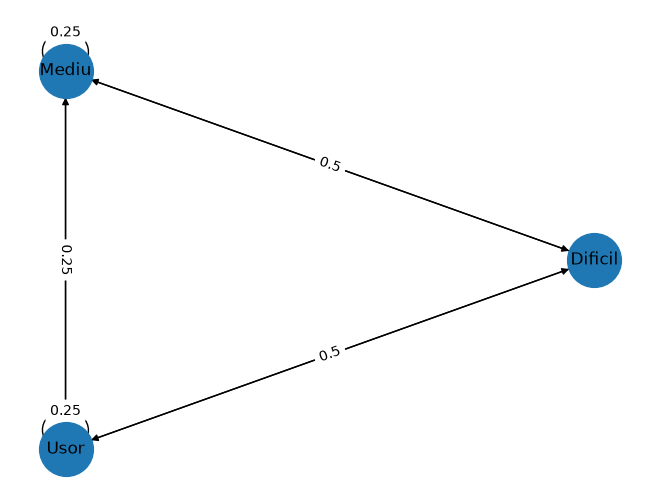

In [6]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.DiGraph()

G.add_edge("Dificil", "Mediu", weight=0.5)
G.add_edge("Dificil", "Usor", weight=0.5)

G.add_edge("Mediu", "Dificil", weight=0.5)
G.add_edge("Mediu", "Mediu", weight=0.25)
G.add_edge("Mediu", "Usor", weight=0.25)

G.add_edge("Usor", "Dificil", weight=0.5)
G.add_edge("Usor", "Mediu", weight=0.25)
G.add_edge("Usor", "Usor", weight=0.25)

pos = nx.circular_layout(G)

nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=1500,
    arrows=True
)

labels = nx.get_edge_attributes(G, "weight")
nx.draw_networkx_edge_labels(G, pos, edge_labels=labels)

plt.show()

In [4]:
cod = {"FB": 0,"B": 1,"S": 2,"NS": 3}

observatii = ["FB", "FB", "S", "B", "B", "S", "B", "B", "NS", "B", "B", "S"]

X = np.array([[cod[x]] for x in observatii])

In [5]:
log_prob, secventa = model.decode(X,algorithm="viterbi")

nume_stari = {0: "Dificil",1: "Mediu",2: "Usor"}

secventa_nume = [nume_stari[s] for s in secventa]

print("Secventa:")
print(secventa_nume)

print("Log-probabilitate:", log_prob)
print("Probabilitate:", np.exp(log_prob))

Secventa:
['Usor', 'Usor', 'Dificil', 'Usor', 'Dificil', 'Mediu', 'Dificil', 'Usor', 'Dificil', 'Usor', 'Dificil', 'Mediu']
Log-probabilitate: -24.582044327855733
Probabilitate: 2.109375000000024e-11
